<a href="https://colab.research.google.com/github/Devaji-Rashmika/2520090152_OSSP/blob/main/DLskilll2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import os
import sys

print("Python Version:", sys.version)
print("PyTorch Version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU Available:", True)
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU Available:", False)

Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch Version: 2.14.1+cu130
GPU Available: True
GPU Name: Tesla T4


In [ ]:
!pip install -q ultralytics fastapi uvicorn python-multipart pillow requests

In [ ]:
from ultralytics import YOLO+
from fastapi import FastAPI, UploadFile, File
from PIL import Image
from io import BytesIO
import torch
import uvicorn
import requests
import os

print("All libraries imported successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
All libraries imported successfully!


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
MODEL_PATH = "/content/drive/MyDrive/VisionPort/models/yolo26n.pt"

model = YOLO(MODEL_PATH)

print("VisionPort YOLO model loaded successfully!")

VisionPort YOLO model loaded successfully!


In [ ]:
from fastapi import FastAPI, UploadFile, File, HTTPException
from PIL import Image
from io import BytesIO

app = FastAPI(
    title="VisionPort",
    description="Vehicle and Traffic Light Detection API",
    version="1.0"
)

# Home endpoint
@app.get("/")
def home():
    return {
        "project": "VisionPort",
        "message": "VisionPort API is running!"
    }

# Object detection endpoint
@app.post("/detect")
async def detect_objects(file: UploadFile = File(...)):

    # Validate image format
    if file.content_type not in ["image/jpeg", "image/png", "image/jpg"]:
        raise HTTPException(
            status_code=400,
            detail="Please upload a JPG or PNG image."
        )

    # Read uploaded image
    contents = await file.read()
    image = Image.open(BytesIO(contents)).convert("RGB")

    # Run YOLO detection
    results = model.predict(
        source=image,
        conf=0.25,
        verbose=False
    )

    target_classes = [
        "car", "motorcycle", "bus",
        "truck", "bicycle", "traffic light"
    ]

    detections = []

    for box in results[0].boxes:
        class_id = int(box.cls[0])
        class_name = model.names[class_id]

        if class_name in target_classes:
            detections.append({
                "object": class_name,
                "confidence": round(float(box.conf[0]), 3),
                "bounding_box": [
                    round(float(x), 2)
                    for x in box.xyxy[0].tolist()
                ]
            })

    return {
        "total_objects": len(detections),
        "detections": detections
    }

print("VisionPort FastAPI application created!")

VisionPort FastAPI application created!


In [ ]:
import threading
import uvicorn
from google.colab.output import eval_js

# Configure the server
config = uvicorn.Config(
    app,
    host="0.0.0.0",
    port=8000,
    log_level="info"
)

server = uvicorn.Server(config)

# Start server in background
server_thread = threading.Thread(
    target=server.run,
    daemon=True
)

server_thread.start()

print("VisionPort API server started!")

VisionPort API server started!


In [ ]:
api_url = eval_js("google.colab.kernel.proxyPort(8000)")

print("VisionPort API URL:", api_url)
print("Swagger Documentation:", api_url + "/docs")

VisionPort API URL: https://8000-gpu-t4-s-usw1b1-1t8ff7hgvyk8h-b.us-west1.prod.r.colab.dev
Swagger Documentation: https://8000-gpu-t4-s-usw1b1-1t8ff7hgvyk8h-b.us-west1.prod.r.colab.dev/docs


In [ ]:

import torch

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
else:
    print("GPU not detected. Check Colab runtime settings.")


CUDA Available: True
GPU Name: Tesla T4
CUDA Version: 13.0


In [ ]:

model.to("cuda")

print("VisionPort YOLO model moved to GPU!")

print("Model device:",
      next(model.model.parameters()).device)


VisionPort YOLO model moved to GPU!
Model device: cuda:0


In [ ]:

# Export YOLO model to ONNX format

onnx_path = model.export(
    format="onnx",
    imgsz=640,
    simplify=True,
    device=0
)

print("VisionPort ONNX export completed!")
print("ONNX Model Path:", onnx_path)


Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/VisionPort/models/yolo26n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (5.3 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime-gpu[cuda]', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 17 packages in 244ms
Prepared 4 packages in 4.38s
Installed 4 packages in 68ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime-gpu==1.31.1
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 5.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18.

In [ ]:

import os

onnx_path = "/content/drive/MyDrive/VisionPort/models/yolo26n.onnx"

print("ONNX file exists:", os.path.exists(onnx_path))

if os.path.exists(onnx_path):
    print("File size:",
          round(os.path.getsize(onnx_path) / (1024 * 1024), 2),
          "MB")

    print("VisionPort ONNX model verified!")


ONNX file exists: True
File size: 9.47 MB
VisionPort ONNX model verified!


In [ ]:

import sys
import torch
import subprocess
import importlib.util

print("Python version:", sys.version)
print("PyTorch CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))

if importlib.util.find_spec("tensorrt"):
    import tensorrt as trt
    print("TensorRT version:", trt.__version__)
else:
    print("TensorRT is not installed yet.")

print("\nGPU Driver Information:")
subprocess.run(["nvidia-smi"])


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch CUDA: 13.0
GPU: Tesla T4
TensorRT is not installed yet.

GPU Driver Information:


CompletedProcess(args=['nvidia-smi'], returncode=0)

In [ ]:

import torch
import importlib.util

print("GPU:", torch.cuda.get_device_name(0))
print("CUDA:", torch.version.cuda)

if importlib.util.find_spec("tensorrt"):
    import tensorrt as trt
    print("TensorRT:", trt.__version__)
else:
    print("TensorRT: Not installed")


GPU: Tesla T4
CUDA: 13.0
TensorRT: Not installed


In [ ]:

!pip install -q tensorrt-cu13

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:

import tensorrt as trt

print("TensorRT installed successfully!")
print("TensorRT version:", trt.__version__)

logger = trt.Logger(trt.Logger.WARNING)
builder = trt.Builder(logger)

print("TensorRT GPU builder initialized!")


TensorRT installed successfully!
TensorRT version: 11.4.0.106
TensorRT GPU builder initialized!


In [ ]:
import torch
import importlib.util

print("GPU:", torch.cuda.get_device_name(0))
print("CUDA:", torch.version.cuda)

print("TensorRT installed:",
      importlib.util.find_spec("tensorrt") is not None)

GPU: Tesla T4
CUDA: 13.0
TensorRT installed: True


In [ ]:
import tensorrt as trt

print("TensorRT Version:", trt.__version__)
print("TensorRT installation successful!")

TensorRT Version: 11.4.0.106
TensorRT installation successful!


In [ ]:
import tensorrt as trt
import torch

print("TensorRT:", trt.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

logger = trt.Logger(trt.Logger.WARNING)
builder = trt.Builder(logger)

print("TensorRT Builder Created:", builder is not None)

TensorRT: 11.4.0.106
CUDA Available: True
GPU: Tesla T4
TensorRT Builder Created: True


In [ ]:
import os

print("ONNX Model Path:", onnx_path)
print("File Exists:", os.path.exists(onnx_path))

if os.path.exists(onnx_path):
    print("ONNX model is ready for TensorRT conversion!")
else:
    print("ONNX model not found. We need to check the export path.")

ONNX Model Path: /content/drive/MyDrive/VisionPort/models/yolo26n.onnx
File Exists: True
ONNX model is ready for TensorRT conversion!


In [ ]:
import onnx

model_onnx = onnx.load(onnx_path)

print("ONNX Model Loaded Successfully!")

print("\nModel Inputs:")
for inp in model_onnx.graph.input:
    print(inp.name)

print("\nModel Outputs:")
for out in model_onnx.graph.output:
    print(out.name)

print("\nONNX Model Check:")
onnx.checker.check_model(model_onnx)
print("Model is valid!")

ONNX Model Loaded Successfully!

Model Inputs:
images

Model Outputs:
output0

ONNX Model Check:
Model is valid!


In [ ]:
import onnx

for inp in model_onnx.graph.input:
    print("Input Name:", inp.name)

    shape = []
    for dim in inp.type.tensor_type.shape.dim:
        shape.append(dim.dim_value if dim.dim_value > 0 else dim.dim_param)

    print("Input Shape:", shape)

Input Name: images
Input Shape: [1, 3, 640, 640]


In [ ]:
import tensorrt as trt

logger = trt.Logger(trt.Logger.WARNING)

builder = trt.Builder(logger)

# TensorRT 11: Explicit batch is the default
network = builder.create_network(0)

parser = trt.OnnxParser(network, logger)

with open(onnx_path, "rb") as f:
    onnx_data = f.read()

success = parser.parse(onnx_data)

print("ONNX Parser Success:", success)

if not success:
    for i in range(parser.num_errors):
        print(parser.get_error(i))
else:
    print("TensorRT successfully parsed the ONNX model!")
    print("Number of layers:", network.num_layers)
    print("Number of inputs:", network.num_inputs)
    print("Number of outputs:", network.num_outputs)

ONNX Parser Success: True
TensorRT successfully parsed the ONNX model!
Number of layers: 443
Number of inputs: 1
Number of outputs: 1


In [ ]:
import tensorrt as trt
import os

# Create builder configuration
config = builder.create_builder_config()

# Set workspace memory to 2 GB
config.set_memory_pool_limit(
    trt.MemoryPoolType.WORKSPACE,
    2 * 1024 * 1024 * 1024
)

print("TensorRT configuration created!")
print("Precision: Using ONNX model precision")
print("Workspace: 2 GB")

# Build TensorRT engine
print("\nBuilding TensorRT engine...")

serialized_engine = builder.build_serialized_network(
    network,
    config
)

if serialized_engine is None:
    print("Engine building failed!")
else:
    engine_path = "/content/drive/MyDrive/VisionPort/models/yolo26n.engine"

    os.makedirs(os.path.dirname(engine_path), exist_ok=True)

    with open(engine_path, "wb") as f:
        f.write(serialized_engine)

    print("\nTensorRT Engine Built Successfully!")
    print("Engine Path:", engine_path)
    print("File Size:", os.path.getsize(engine_path) / (1024 * 1024), "MB")

TensorRT configuration created!
Precision: Using ONNX model precision
Workspace: 2 GB

Building TensorRT engine...

TensorRT Engine Built Successfully!
Engine Path: /content/drive/MyDrive/VisionPort/models/yolo26n.engine
File Size: 158.60810470581055 MB


In [ ]:
import os

engine_path = "/content/drive/MyDrive/VisionPort/models/yolo26n.engine"

if os.path.exists(engine_path):
    print("Engine File Found!")
    print("File Size:", round(os.path.getsize(engine_path) / (1024 * 1024), 2), "MB")
else:
    print("Engine File Not Found!")

Engine File Found!
File Size: 158.61 MB


In [ ]:
import tensorrt as trt

logger = trt.Logger(trt.Logger.WARNING)

runtime = trt.Runtime(logger)

with open(engine_path, "rb") as f:
    engine_data = f.read()

engine = runtime.deserialize_cuda_engine(engine_data)

if engine is not None:
    print("TensorRT Engine Loaded Successfully!")
    print("Engine is ready for inference!")
else:
    print("Engine loading failed!")

TensorRT Engine Loaded Successfully!
Engine is ready for inference!


In [ ]:
import tensorrt as trt

print("Engine Input/Output Details:")

for i in range(engine.num_io_tensors):
    name = engine.get_tensor_name(i)
    shape = engine.get_tensor_shape(name)
    dtype = engine.get_tensor_dtype(name)
    mode = engine.get_tensor_mode(name)

    print("\nTensor Name:", name)
    print("Shape:", shape)
    print("Data Type:", dtype)
    print("Mode:", mode)

Engine Input/Output Details:

Tensor Name: images
Shape: (1, 3, 640, 640)
Data Type: DataType.FLOAT
Mode: TensorIOMode.INPUT

Tensor Name: output0
Shape: (1, 84, 8400)
Data Type: DataType.FLOAT
Mode: TensorIOMode.OUTPUT


In [ ]:
from ultralytics import YOLO

# Load TensorRT engine
trt_model = YOLO(engine_path, task="detect")

print("VisionPort TensorRT Model Loaded!")
print("Model Type:", type(trt_model).__name__)
print("Engine Path:", engine_path)

VisionPort TensorRT Model Loaded!
Model Type: YOLO
Engine Path: /content/drive/MyDrive/VisionPort/models/yolo26n.engine


Loading /content/drive/MyDrive/VisionPort/models/yolo26n.engine for TensorRT inference...

image 1/1 /content/bus.jpg: 640x640 4 class0s, 1 class5, 7.1ms
Speed: 56.1ms preprocess, 7.1ms inference, 43.7ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
Detected Objects:
class5: 90.30%
class0: 85.48%
class0: 84.50%
class0: 83.73%
class0: 55.67%


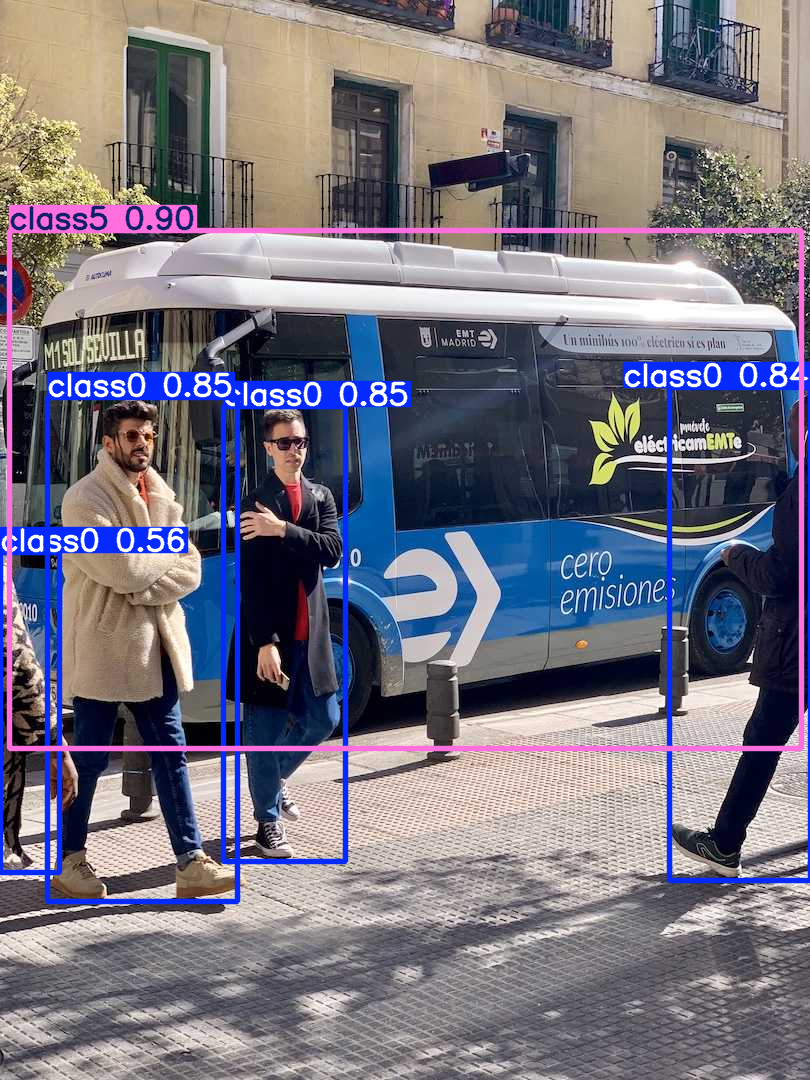

VisionPort TensorRT inference completed!


In [ ]:
from google.colab.patches import cv2_imshow

# Run TensorRT inference
results = trt_model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    imgsz=640,
    conf=0.25,
    device=0,
    save=True
)

# Display detection results
for result in results:
    print("Detected Objects:")

    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        print(
            f"{result.names[class_id]}: "
            f"{confidence:.2%}"
        )

    # Display annotated image
    annotated_image = result.plot()
    cv2_imshow(annotated_image)

print("VisionPort TensorRT inference completed!")

In [ ]:
from fastapi import FastAPI, UploadFile, File, HTTPException
from PIL import Image
from io import BytesIO

app = FastAPI(
    title="VisionPort Detection API",
    description="YOLO TensorRT Object Detection",
    version="1.0"
)

# Home endpoint
@app.get("/")
def home():
    return {
        "project": "VisionPort",
        "status": "Running",
        "model": "YOLO TensorRT"
    }


# Object detection endpoint
@app.post("/detect")
async def detect(file: UploadFile = File(...)):

    if not file.content_type or not file.content_type.startswith("image/"):
        raise HTTPException(
            status_code=400,
            detail="Please upload a valid image"
        )

    try:
        contents = await file.read()
        image = Image.open(BytesIO(contents)).convert("RGB")

        results = trt_model.predict(
            source=image,
            imgsz=640,
            conf=0.25,
            device=0,
            verbose=False
        )

        detections = []

        for box in results[0].boxes:
            class_id = int(box.cls[0])
            confidence = float(box.conf[0])
            coordinates = box.xyxy[0].tolist()

            detections.append({
                "object": results[0].names[class_id],
                "confidence": round(confidence, 4),
                "bounding_box": coordinates
            })

        return {
            "project": "VisionPort",
            "total_objects": len(detections),
            "detections": detections
        }

    except Exception as e:
        raise HTTPException(status_code=500, detail=str(e))


print("VisionPort Detection API Created!")
print("GET /")
print("POST /detect")

VisionPort Detection API Created!
GET /
POST /detect


In [ ]:
!pip install fastapi uvicorn python-multipart requests

In [ ]:
import threading
import uvicorn

def run_server():
    uvicorn.run(
        app,
        host="0.0.0.0",
        port=8000,
        log_level="info"
    )

server_thread = threading.Thread(
    target=run_server,
    daemon=True
)

server_thread.start()

print("VisionPort API server started!")

VisionPort API server started!


INFO:     Started server process [389]
INFO:     Waiting for application startup.
INFO:     Application startup complete.


In [ ]:
import requests
import time

time.sleep(3)

response = requests.get("http://127.0.0.1:8000/")

print("Status Code:", response.status_code)
print("API Response:", response.json())

In [ ]:
import requests

# Download sample image
image_url = "https://ultralytics.com/images/bus.jpg"
image_response = requests.get(image_url)
image_response.raise_for_status()

# Send image to VisionPort API
files = {
    "file": ("bus.jpg", image_response.content, "image/jpeg")
}

response = requests.post(
    "http://127.0.0.1:8000/detect",
    files=files
)

print("Status Code:", response.status_code)
print("\nDetection Results:")

print(response.json())

INFO:     127.0.0.1:51434 - "POST /detect HTTP/1.1" 200 OK
Status Code: 200

Detection Results:
{'total_objects': 1, 'detections': [{'object': 'bus', 'confidence': 0.881, 'bounding_box': [0.0, 230.48, 803.2, 750.7]}]}


In [ ]:
from google.colab.output import eval_js

# Generate Colab proxy URL
public_url = eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

print("VisionPort API URL:", public_url)
print("Swagger Documentation:", public_url + "/docs")

VisionPort API URL: https://8000-gpu-t4-s-usw4b1-1be7lpw0fince-b.us-west4.prod.r.colab.dev
Swagger Documentation: https://8000-gpu-t4-s-usw4b1-1be7lpw0fince-b.us-west4.prod.r.colab.dev/docs


In [ ]:
print("VisionPort API Base URL:")
print(public_url)

print("\nDetection Endpoint:")
print(public_url + "/detect")

print("\nSwagger Documentation:")
print(public_url + "/docs")

VisionPort API Base URL:
https://8000-gpu-t4-s-usw4b1-1be7lpw0fince-b.us-west4.prod.r.colab.dev

Detection Endpoint:
https://8000-gpu-t4-s-usw4b1-1be7lpw0fince-b.us-west4.prod.r.colab.dev/detect

Swagger Documentation:
https://8000-gpu-t4-s-usw4b1-1be7lpw0fince-b.us-west4.prod.r.colab.dev/docs
